# Mid Assignment: CNN Development on a Custom Dataset 

**Course:** COE4234: Computer Vision and Pattern Recognition 

**Section:** E

**ID:** 23-54734-3 

**Name:** Ahmad Zubayer

**Dataset:** EuroSAT (Sentinel-2 satellite image patches, 10 land-use classes)

**Kaggle Link:** [https://www.kaggle.com/code/ahmadzubayer/cnn-23-54734-3](https://www.kaggle.com/code/ahmadzubayer/cnn-23-54734-3)

**GitHub Repo:** [github.com/AhmadZubayer/cvpr-assignment-mid-cnn](https://github.com/AhmadZubayer/cvpr-assignment-mid-cnn)

---
**Abstract**
Satellite images can show how land is being used, but sorting them by hand is slow. This project trains a convolutional neural network from scratch to do it automatically. The EuroSAT dataset was used: 27,000 Sentinel-2 images of 64×64 pixels across 10 land types such as forest, river and residential. The network has three convolutional blocks and uses global average pooling, giving only 289,194 parameters. The data was split 70/15/15 and trained for 25 epochs using Adam with a learning rate scheduler. The model reached 96.62% accuracy on unseen test images at a size of just 1.12 MB, small enough to run on modest hardware and could be integrated into a larger software engine, a land-monitoring pipeline or GIS tool that ingests new satellite tiles, classifies them automatically, and flags changes in land use over time. Future work includes using infrared bands to separate crop types more reliably.

### Dataset Specification

| Property | Value |
|---|---|
| Name | EuroSAT |
| Source | Kaggle (`apollo2506/eurosat-dataset`) |
| Origin | Sentinel-2 satellite, European Space Agency |
| Access | Open access |
| Total images | 27,000 |
| Number of classes | 10 |
| Image dimensions | 64 × 64 pixels |
| Channels | 3 (RGB) |
| File format | JPG |
| Ground sampling distance | 10 metres per pixel |
| Images per class | 2,000 – 3,000 |
| Imbalance ratio | 1.5 : 1 (largest to smallest class) |
| Folder structure | One directory per class |
| Split used | 70% train / 15% validation / 15% test, stratified |
| Split sizes | 18,900 / 4,050 / 4,050 |
| Classes | AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake |

### Workflow

```
                    EuroSAT dataset
             27,000 images · 10 classes · 64×64
                           |
         +-----------------+-----------------+
         |                 |                 |
       Train           Validation           Test
   18,900 images     4,050 images      4,050 images
    (augmented)        (clean)         (held out)
         |                 |                 |
         +--------+--------+                 |
                  |                          |
      Training loop · 25 epochs              |
    Custom CNN · Adam · LR scheduler         |
                  |                          |
          Best checkpoint                    |
        1.12 MB · epoch 24                   |
                  |                          |
                  +------------+-------------+
                               |
                      Test evaluation
                       96.62% accuracy
```

The training and validation sets both feed the training loop: the training set updates the weights, while the validation set is measured after each epoch to monitor generalisation, drive the learning rate scheduler, and decide when to save a checkpoint. The test set bypasses training entirely and is used once, at the end, together with the best saved checkpoint.

### Notebook Structure
1. Import Libraries
2. Load and Explore Dataset
3. Setting Hyperparameters
4. Data Preprocessing & Augmentation
5. Define CNN Architecture
6. Training Loop with Validation
7. Evaluate Model on Test Set
8. Visualizations
9. Analysis & Discussion of Results
10. Validation of Basic Design Choices
11. Conclusions & Future Work
12. Save the Model
13. Load and Spot Check
14. Acknowledgement

## Step 1: Import Libraries & Setup

The required libraries are loaded, randomness is fixed, and the GPU is selected.

### Main steps
1. PyTorch and its neural network layers were imported.
2. torchvision's dataset loaders and transforms were imported.
3. NumPy and matplotlib were imported for maths and plotting.
4. The random seed was fixed at 42.
5. The device was set to GPU if available, otherwise CPU.

In [15]:
# Import necessary libraries
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, Subset
import torch
import torch.nn as nn

import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Fix the random seed for weight initialization, data augmentation, shuffling, PyTorch, and NumPy randomness
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Check if GPU is enabled in kaggle
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## Step 2: Load & Explore Dataset
The EuroSAT dataset is fetched and its location on disk is stored. The correct class folder is found automatically, then the class counts and sample images are inspected.

### Main steps
1. `kagglehub` was imported.
2. The EuroSAT dataset was requested by its Kaggle slug.
3. The returned folder path was printed.
4.  `find_image_root` walked the dataset tree and returned the folder holding the 10 class sub-folders.
5. The dataset was loaded once without transforms to read class names and labels.
6. Images per class were counted and printed.
7. The class distribution was plotted as a bar chart.
8. One sample image from each class was displayed.

### Dataset description

| Property | Value |
|---|---|
| Source | Sentinel-2 satellite (European Space Agency), via Kaggle |
| Images | ~27,000 |
| Classes | 10 |
| Size | 64 × 64 pixels, RGB, JPG |
| Ground resolution | 10 metres per pixel |
| Balance | 2,000–3,000 images per class |

Classes: AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake.


Path to dataset files: /kaggle/input/datasets/apollo2506/eurosat-dataset
Image root: /kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT
Class folders: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake', 'label_map.json', 'test.csv', 'train.csv', 'validation.csv']
Number of classes: 10
Total images     : 27000
Classess and Indices:  {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

AnnualCrop               3000 images
Forest                   3000 images
HerbaceousVegetation     3000 images
Highway                  2500 images
Industrial               2500 images
Pasture                  2000 images
PermanentCrop            2500 images
Residential              3000 images
River                    2500 images
SeaLake                  3000 images

Imbalance ratio: 1.50 : 1  (near 1 

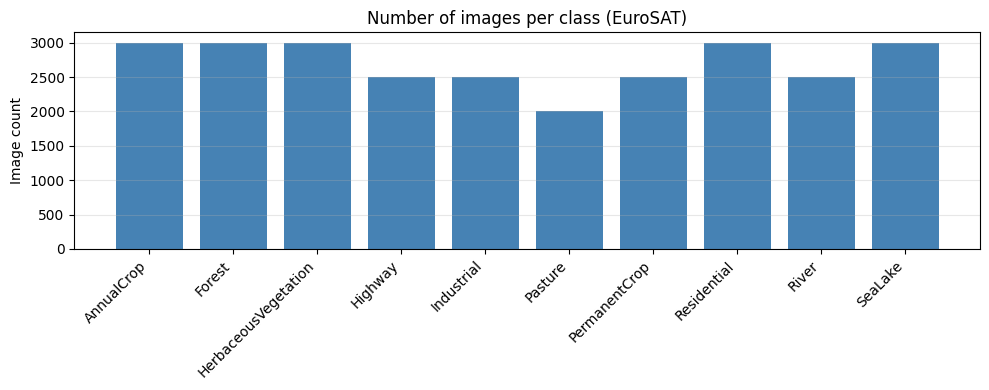

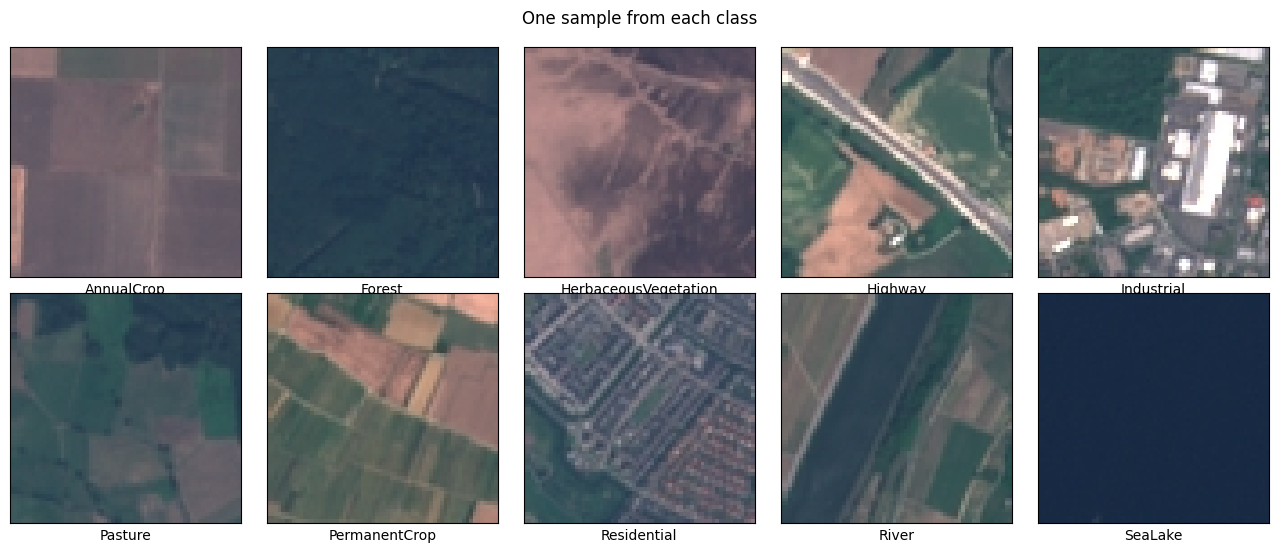

In [16]:
# load and explore dataset
import kagglehub
path = kagglehub.dataset_download("apollo2506/eurosat-dataset")
print("Path to dataset files:", path)

def find_image_root(base_path):
    for root, dirs, files in os.walk(base_path):
        if "allband" in root.lower():          # skip the multispectral .tif folder
            continue
        class_dirs = sorted([d for d in dirs if not d.startswith(".")])
        if len(class_dirs) >= 10:
            sample_dir = os.path.join(root, class_dirs[0])
            images = [f for f in os.listdir(sample_dir) if f.lower().endswith(".jpg")]
            if len(images) > 0:
                return root
    return None

data_dir = find_image_root(path)
print("Image root:", data_dir)
print("Class folders:", sorted(os.listdir(data_dir)))

# ---- Explore the dataset: class names, counts, and sample images ----
peek = datasets.ImageFolder(data_dir)
class_names = peek.classes
num_classes = len(class_names)
targets_all = np.array(peek.targets)

print('Number of classes:', num_classes)
print('Total images     :', len(peek))
print('Classess and Indices: ', peek.class_to_idx)
print()

counts = np.bincount(targets_all, minlength=num_classes)
for name, c in zip(class_names, counts):
    print(f'{name:<22} {c:>6} images')

print()
print(f'Imbalance ratio: {counts.max() / counts.min():.2f} : 1  (near 1 means balanced)')
print('Image size:', peek[0][0].size, '(width x height)')

# Bar chart of class distribution
plt.figure(figsize=(10, 4))
plt.bar(class_names, counts, color='steelblue')
plt.title('Number of images per class (EuroSAT)')
plt.ylabel('Image count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# One sample image from each class
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(13, 5.5))
for class_idx, ax in enumerate(axes.flat):
    first = int(np.where(targets_all == class_idx)[0][0])   # first image of this class
    img, label = peek[first]
    ax.imshow(img)
    ax.set_xlabel(class_names[label])
    ax.set(xticks=[], yticks=[])
plt.suptitle('One sample from each class')
plt.tight_layout()
plt.show()

## Step 3: Setting Hyperparameters
All tunable values are defined in one place.

### Main steps
1. The input image size was set to 64.
2. The batch size was set to 64.
3. The starting learning rate was set to 1e-3.
4. The number of epochs was set to 25.

### Variables

| Name | Value | What it is |
|---|---|---|
| `size` | 64 | Height and width of the image fed to the CNN, in pixels |
| `batch_size` | 64 | Number of images processed before each weight update |
| `learning_rate` | 1e-3 | Step size for Adam, equal to 0.001 |
| `epoch_number` | 25 | Number of complete passes over the training set |

In [17]:
## HyperParameters 
size          = 64      
batch_size    = 64     
learning_rate = 1e-3   
epoch_number  = 25      

## Step 4: Data Preprocessing & Augmentation

Two transform pipelines are defined, the dataset is split into train, validation and test, and the three loaders are built.

### Main steps
1. A training pipeline with random augmentation was defined.
2. An evaluation pipeline without randomness was defined.
3. Two `ImageFolder` views of the same folder were created, one per pipeline.
4. The 27,000 image indices were split 70 / 15 / 15, stratified by class.
5. `Subset` was used to take training indices from the augmented view and validation and test indices from the clean view.
6. Three `DataLoader` objects were built and one batch was checked.

## Augmentation
1. random augmentation so the model cannot memorise exact images
2. Vertical & Horizontal Flips & Subtle rotation [Satelite Images are mostly vertical]
3. No color jitter

### Variables

| Name | What it is |
|---|---|
| `train_transform` | Resize, random horizontal flip, random vertical flip, ±15° rotation, convert to tensor |
| `eval_transform` | Resize and convert to tensor only |
| `train_view` | `ImageFolder` over the data folder, carrying `train_transform` |
| `eval_view` | `ImageFolder` over the same folder, carrying `eval_transform` |
| `all_indices` | Array 0 to 26,999, one ticket number per image |
| `all_targets` | Class index 0–9 for each image, aligned with `all_indices` |
| `train_idx`, `val_idx`, `test_idx` | The index numbers assigned to each split |
| `train_data`, `val_data`, `test_data` | `Subset` objects holding 18,900 / 4,050 / 4,050 images |
| `trn_dl`, `val_dl`, `test_dl` | Loaders producing batches of 64 |
|`num_workers` | how many background processes prepare the data |

In [18]:
# Data Preprocessing & Augmentation
from sklearn.model_selection import train_test_split

# Augmentation
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),    
    transforms.RandomVerticalFlip(),     
    transforms.RandomRotation(15),        
    transforms.ToTensor()                
])

# An evaluation pipeline without randomness was defined.
eval_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Two ImageFolder views of the same folder were created, one per pipeline.
train_view = datasets.ImageFolder(data_dir, transform=train_transform)
eval_view  = datasets.ImageFolder(data_dir, transform=eval_transform)

all_indices = np.arange(len(eval_view))
all_targets = np.array(eval_view.targets)

# Split 70% train / 15% validation / 15% test
train_idx, holdout_idx = train_test_split(
    all_indices, test_size=0.30, stratify=all_targets, random_state=SEED)

val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, stratify=all_targets[holdout_idx], random_state=SEED)

train_data = Subset(train_view, train_idx)   # augmented
val_data   = Subset(eval_view,  val_idx)     # clean
test_data  = Subset(eval_view,  test_idx)    # clean

print('Dataset Summary')
print('Train Data      : ', len(train_data))
print('Validation Data : ', len(val_data))
print('Test Data       : ', len(test_data))
print('Classess and Indices: ', train_view.class_to_idx)

# Data loaders - shuffle training data
trn_dl  = DataLoader(train_data, batch_size=batch_size, shuffle=True,  num_workers=2)
val_dl  = DataLoader(val_data,   batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data,  batch_size=batch_size, shuffle=False, num_workers=2)

print()
print(f'Batches per epoch -> train: {len(trn_dl)}, val: {len(val_dl)}, test: {len(test_dl)}')

#  check on one batch
images, labels = next(iter(trn_dl))
print('One batch of images:', images.shape)  
print('Pixel range        :', f'{images.min():.2f} to {images.max():.2f}')

Dataset Summary
Train Data      :  18900
Validation Data :  4050
Test Data       :  4050
Classess and Indices:  {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

Batches per epoch -> train: 296, val: 64, test: 64
One batch of images: torch.Size([64, 3, 64, 64])
Pixel range        : 0.00 to 1.00


## Step 5: Define the CNN Architecture, Optimizer and Scheduler
The custom CNN is defined and built, the loss function, optimizer and learning rate scheduler are attached, and the layer summary is printed.

### Main steps
1. Three convolutional blocks were stacked, each containing two convolutions followed by a max pool.
2. Batch normalisation and ReLU were applied after every convolution.
3. Global average pooling collapsed each feature map to a single value.
4. Dropout and a final linear layer produced 10 class scores.
5. `CrossEntropyLoss` and the Adam optimizer were created inside `get_model()`.
6. The model was built and a `ReduceLROnPlateau` scheduler was attached.
7. The layer table, parameter count and approximate file size were printed.

### Shape through the network

| Stage | Map size | Channels |
|---|---|---|
| Input | 64 × 64 | 3 |
| Block 1 | 32 × 32 | 32 |
| Block 2 | 16 × 16 | 64 |
| Block 3 | 8 × 8 | 128 |
| After GAP | 1 × 1 | 128 |
| Output | — | 10 |

### Variable 

| Name | What it is |
|---|---|
| `get_model()` | Builds and returns the model, loss function and optimizer together |
| `nn.Conv2d(in, out, kernel_size=3, padding=1)` | Applies `out` filters of size 3 × 3; padding keeps width and height unchanged |
| `nn.BatchNorm2d(n)` | Normalises the `n` channels leaving the convolution |
| `nn.ReLU()` | Non-linearity; sets negative values to zero |
| `nn.MaxPool2d(2)` | Halves width and height by keeping the largest value in each 2 × 2 window |
| `nn.AdaptiveAvgPool2d(1)` | Global average pooling; averages each map to one number |
| `nn.Dropout(0.3)` | Randomly zeroes 30% of the 128 features during training |
| `nn.Linear(128, num_classes)` | Final layer producing one raw score per class |
| `loss_fn` | `CrossEntropyLoss`, the loss for single-label multi-class problems |
| `optimizer` | Adam, which updates the weights using the gradients |


In [19]:
#  Define CNN Architecture 
!pip install torchsummary -q

from torch.optim import SGD, Adam
from torchsummary import summary


def get_model():
    model = nn.Sequential(
        # Feature Extraction
        # Block 1: 3 x 64 x 64 -> 32 x 32 x 32
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.Conv2d(32, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2: 32 x 32 x 32 -> 64 x 16 x 16
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3: 64 x 16 x 16 -> 128 x 8 x 8
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.Conv2d(128, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.AdaptiveAvgPool2d(1),            # GAP: 128 x 8 x 8 -> 128 x 1 x 1
        nn.Flatten(),                       # -> 128
        nn.Dropout(0.3),
        nn.Linear(128, num_classes)         # 10 outputs
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer


# Build the model, loss function and optimizer
model, loss_fn, optimizer = get_model()

# Halve the learning rate when validation accuracy stalls for 2 epochs.
# Added after an initial run showed an unstable validation curve under a constant LR.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

# Layer-by-layer summary and model size
summary(model, input_size=(3, size, size))

total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters : {total_params:,}')
print(f'Approx file size : {total_params * 4 / 1024**2:.2f} MB')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 32, 64, 64]           9,248
       BatchNorm2d-5           [-1, 32, 64, 64]              64
              ReLU-6           [-1, 32, 64, 64]               0
         MaxPool2d-7           [-1, 32, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          18,496
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,928
      BatchNorm2d-12           [-1, 64, 32, 32]             128
             ReLU-13           [-1, 64, 32, 32]               0
        MaxPool2d-14           [-1, 64,

## Step 6: Training Loop with Validation
The training and evaluation functions are defined, then the model is trained for 25 epochs with the best weights saved whenever validation accuracy improves.

### Main steps
1. `train_one_epoch` was defined to run one full pass over the training set and update the weights.
2. `validation` was defined to measure loss and accuracy without learning.
3. `predictOne` was defined to display a single image with its predicted class and confidence.
4. Four lists were created to record loss and accuracy per epoch.
5. Each epoch trained, validated, stepped the scheduler, and saved the weights on improvement.
6. Loss, accuracy and the current learning rate were printed each epoch.

### The five steps inside the training loop

1. `optimizer.zero_grad()` — clear the previous batch's gradients.
2. `model(x)` — forward pass, produce predictions.
3. `loss_fn(prediction, y)` — measure the error.
4. `batch_loss.backward()` — backpropagation.
5. `optimizer.step()` — update the weights.
   
### Variable

| Name | What it is |
|---|---|
| `data_loader` | The loader supplying batches, passed in so one function serves train, validation and test |
| `model.train()` | Enables dropout; batch normalisation uses the current batch's statistics |
| `model.eval()` | Disables dropout; batch normalisation uses its stored running averages |
| `@torch.no_grad()` | Disables gradient tracking, since no learning occurs |
| `prediction.argmax(-1)` | Index of the highest of the 10 class scores |
| `torch.softmax` | Converts the 10 raw scores into probabilities, used only for display |
| `train_losses`, `train_accuracies` | One value per epoch from the training set |
| `val_losses`, `val_accuracies` | One value per epoch from the validation set |
| `best_val_accuracy` | Highest validation accuracy seen so far |
| `CHECKPOINT` | Filename for the saved weights, `CNN_EuroSAT.pth` |
| `flag` | Marker printed when an epoch produced a new best |
| `optimizer.param_groups[0]['lr']` | Current learning rate, printed to show the scheduler acting |


In [20]:
# Training Loop with Validation 

def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()                            # Dropout ON
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()               
        prediction = model(x)               
        batch_loss = loss_fn(prediction, y) 
        batch_loss.backward()               
        optimizer.step()                     

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()                            
def validation(data_loader, model, loss_fn):
    model.eval()                            
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)


@torch.no_grad()
def predictOne(model, img, classes):
    model.eval()
    x = img.unsqueeze(0).to(device)                  
    pred = torch.softmax(model(x), dim=-1)
    confidence, index = pred.max(-1)
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(img.permute(1, 2, 0).numpy())        
    plt.axis('off')
    plt.title(f'{classes[index.item()]} , Confidence: {confidence.item()*100:0.2f}%')
    plt.show()


## Training Loop
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_accuracy = 0.0
CHECKPOINT = 'CNN_EuroSAT.pth'

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    # adjust the learning rate on validation accuracy
    scheduler.step(v_acc)                   

    # Save the weights whenever validation accuracy improves
    flag = ''
    if v_acc > best_val_accuracy:
        best_val_accuracy = v_acc
        torch.save(model.state_dict(), CHECKPOINT)
        flag = '  <-- highest'

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%"
          f" | LR: {optimizer.param_groups[0]['lr']:.1e}{flag}")

print()
print(f'Best validation accuracy: {best_val_accuracy*100:.2f}%  (saved to {CHECKPOINT})')

Epoch [1/25] | Train Loss: 0.9154 | Train Accuracy: 68.59% | Val Loss: 1.0952 | Val Accuracy: 62.12% | LR: 1.0e-03  <-- highest
Epoch [2/25] | Train Loss: 0.6247 | Train Accuracy: 78.75% | Val Loss: 0.6804 | Val Accuracy: 76.91% | LR: 1.0e-03  <-- highest
Epoch [3/25] | Train Loss: 0.5252 | Train Accuracy: 82.12% | Val Loss: 0.6737 | Val Accuracy: 76.17% | LR: 1.0e-03
Epoch [4/25] | Train Loss: 0.4389 | Train Accuracy: 84.96% | Val Loss: 1.0390 | Val Accuracy: 70.42% | LR: 1.0e-03
Epoch [5/25] | Train Loss: 0.3827 | Train Accuracy: 87.02% | Val Loss: 0.8875 | Val Accuracy: 75.53% | LR: 5.0e-04
Epoch [6/25] | Train Loss: 0.2939 | Train Accuracy: 90.16% | Val Loss: 0.9490 | Val Accuracy: 74.15% | LR: 5.0e-04
Epoch [7/25] | Train Loss: 0.2743 | Train Accuracy: 90.65% | Val Loss: 0.4188 | Val Accuracy: 86.69% | LR: 5.0e-04  <-- highest
Epoch [8/25] | Train Loss: 0.2535 | Train Accuracy: 91.54% | Val Loss: 0.2811 | Val Accuracy: 90.27% | LR: 5.0e-04  <-- highest
Epoch [9/25] | Train Loss: 0

## Step 7: Evaluate the Model on the Test Set
The best saved weights are loaded and scored once on the held-out test set, then broken down per class and as a confusion matrix.

### Main steps
1. The best checkpoint was loaded back into the model.
2. Test loss and overall accuracy were measured with `validation`.
3. `collect_predictions` gathered every predicted and true label from the test set.
4. A per-class report of precision, recall and F1 was printed.
5. The confusion matrix was plotted with counts written in each cell.
6. The single most frequent misclassification was identified automatically.


### Variable

| Name | What it is |
|---|---|
| `test_loss`, `test_acc` | Overall loss and accuracy on the 4,050 test images |
| `collect_predictions` | Returns the true and predicted class index for every test image |
| `y_true` | The correct class for each test image |
| `y_pred` | The model's predicted class for each test image |
| `classification_report` | Per-class precision, recall and F1 |
| `cm` | Confusion matrix; rows are true classes, columns are predicted classes |
| `cm_offdiag` | The matrix with its diagonal zeroed, leaving only the errors |

### Metrics used

| Metric | Meaning |
|---|---|
| Accuracy | Fraction of all test images labelled correctly |
| Precision | Of everything predicted as a class, how much truly belonged to it |
| Recall | Of all images truly in a class, how many were found |
| F1 | The balance between precision and recall |
| Confusion matrix | Which classes are mistaken for which; the diagonal is correct, everything off it is an error |


Test Loss : 0.1037 , Test Accuracy: 96.62%

Per-class performance on the test set
                      precision    recall  f1-score   support

          AnnualCrop     0.9316    0.9378    0.9347       450
              Forest     0.9868    0.9956    0.9912       450
HerbaceousVegetation     0.9342    0.9778    0.9555       450
             Highway     0.9606    0.9760    0.9683       375
          Industrial     0.9760    0.9760    0.9760       375
             Pasture     0.9696    0.9567    0.9631       300
       PermanentCrop     0.9579    0.9093    0.9330       375
         Residential     0.9955    0.9867    0.9911       450
               River     0.9542    0.9440    0.9491       375
             SeaLake     0.9955    0.9889    0.9922       450

            accuracy                         0.9662      4050
           macro avg     0.9662    0.9649    0.9654      4050
        weighted avg     0.9664    0.9662    0.9661      4050



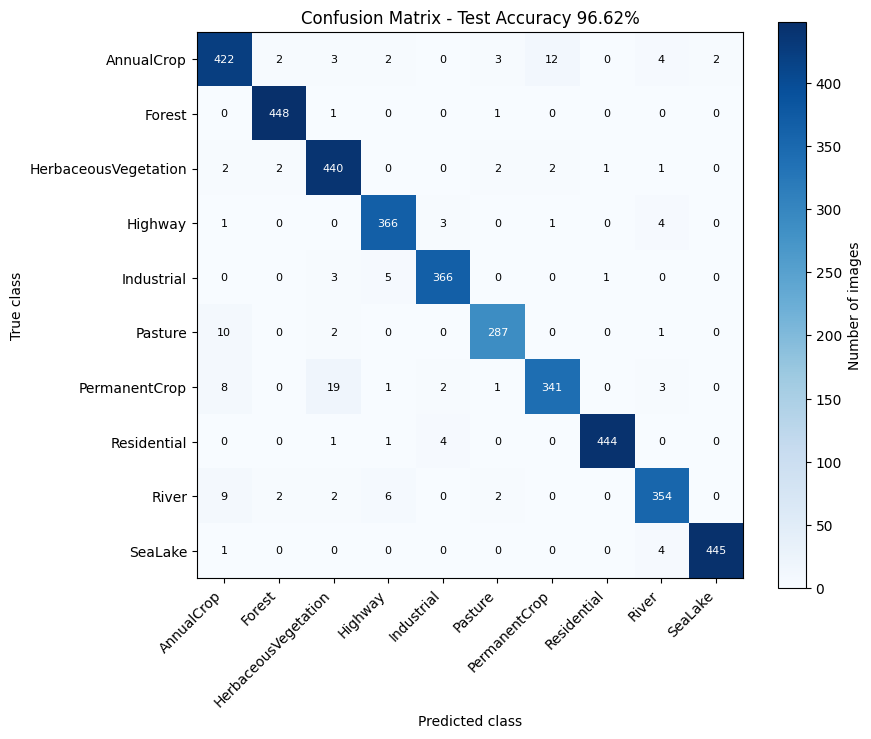

Most frequent mistake: 19 'PermanentCrop' images predicted as 'HerbaceousVegetation'


In [21]:
# Evaluate Model on Test Set 
from sklearn.metrics import classification_report, confusion_matrix

# Load the BEST weights saved during training
model.load_state_dict(torch.load(CHECKPOINT))

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')
print()


# Collect every prediction and every true label from the test set
@torch.no_grad()
def collect_predictions(data_loader, model):
    model.eval()
    y_true, y_pred = [], []
    for x, y in data_loader:
        x = x.to(device)
        preds = model(x).argmax(-1).cpu()
        y_true.extend(y.tolist())
        y_pred.extend(preds.tolist())
    return np.array(y_true), np.array(y_pred)

y_true, y_pred = collect_predictions(test_dl, model)

print('Per-class performance on the test set')
print('=' * 62)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax, label='Number of images')

ax.set_xticks(range(num_classes)); ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticks(range(num_classes)); ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title(f'Confusion Matrix - Test Accuracy {test_acc*100:.2f}%')


threshold = cm.max() / 2
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > threshold else 'black')
plt.tight_layout()
plt.show()

# Report the single worst confusion for the analysis section
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
i, j = np.unravel_index(cm_offdiag.argmax(), cm_offdiag.shape)
print(f"Most frequent mistake: {cm_offdiag[i, j]} '{class_names[i]}' images predicted as '{class_names[j]}'")

## Step 8: Visualizations

The per-epoch training and validation records are plotted so the course of training can be read directly.

### Main steps
1. An epoch axis from 1 to 25 was built.
2. Training and validation loss were plotted together on the left.
3. Training and validation accuracy were plotted together on the right.
4. The final accuracies, their gap, and the best epoch were printed.

### Variable 

| Name | What it is |
|---|---|
| `epochs` | Array 1 to 25, used as the x-axis |
| `train_losses`, `val_losses` | One loss value per epoch, recorded during training |
| `train_accuracies`, `val_accuracies` | One accuracy value per epoch |
| `np.argmax(val_accuracies)` | Position of the highest validation accuracy, converted to an epoch number |


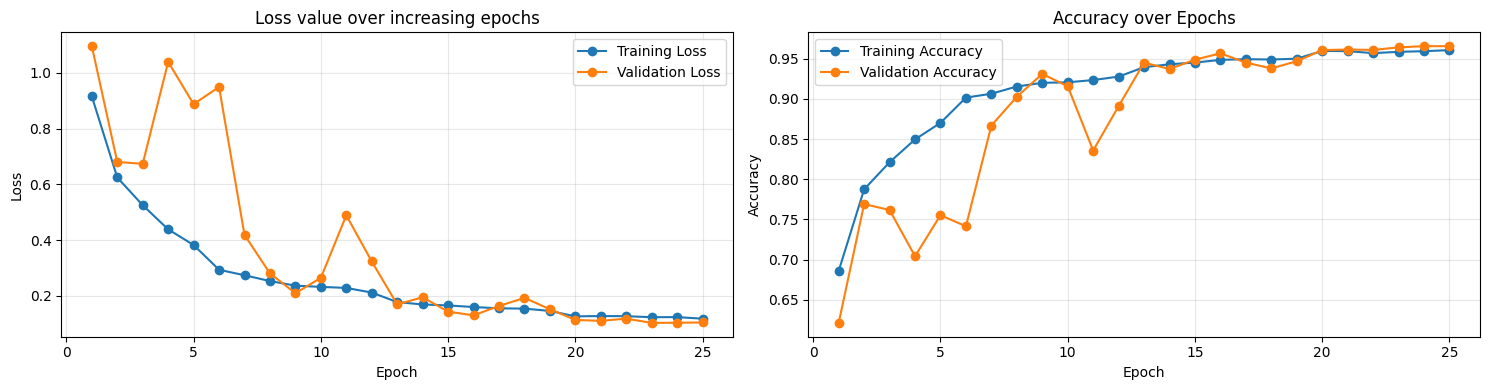

Final training accuracy  : 96.07%
Final validation accuracy: 96.57%
Best validation accuracy : 96.57% at epoch 24


In [22]:
# Visualizations 
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Final training accuracy  : {train_accuracies[-1]*100:.2f}%')
print(f'Final validation accuracy: {val_accuracies[-1]*100:.2f}%')
print(f'Best validation accuracy : {max(val_accuracies)*100:.2f}% at epoch {int(np.argmax(val_accuracies))+1}')

## 9. Analysis and Discussion of Results

### 9.1 Overall performance

The trained CNN was evaluated once on the 4,050 held-out test images. The test set was never used for training and never used to select the best epoch.

| Measure | Value |
|---|---|
| Test accuracy | 96.62% |
| Test loss | 0.1037 |
| Macro average F1 | 0.9654 |
| Weighted average F1 | 0.9661 |
| Best validation accuracy | 96.57% (epoch 24) |
| Total parameters | 289,194 |
| Saved model size | 1.12 MB |

Random guessing across 10 classes would score 10%. Out of 4,050 test images, 3,913 were classified correctly and 137 were wrong. Macro F1 (0.9654) and weighted F1 (0.9661) are almost identical. Macro treats every class equally while weighted accounts for class size, so their agreement shows no class was sacrificed to score well on the larger ones. Second, validation accuracy (96.57%) and test accuracy (96.62%) differ by only 0.05 percentage points. Since the best epoch was chosen using validation data there was a risk of over-fitting to that set, and the near-identical test score shows this did not happen.


### 9.2 Training behaviour and the learning rate schedule

(View Figure:  the loss and accuracy curves in Section 7.)

| Stage | Epochs | What the curves show |
|---|---|---|
| Rapid learning | 1–9 | Training loss falls from 0.9154 to 0.2370; validation accuracy rises from 62.12% to 93.11% |
| Unstable middle | 10–12 | Validation accuracy swings between 83.58% and 91.58% while training accuracy climbs smoothly |
| Settling | 13–18 | Validation accuracy holds between 93.73% and 95.68% with smaller swings |
| Converged | 19–25 | Validation accuracy sits between 94.69% and 96.57%; validation loss flattens near 0.10 |

The feature of the accuracy curve (right panel) is that the **training line is smooth while the validation line is jagged**, especially before epoch 13. This is the opposite of what simple overfitting would produce, and it has two causes: 

The first is step size. The learning rate started at 1e-3 and stayed there for four epochs. Backpropagation decides which direction each weight should move; the learning rate decides how far. Large steps help early, when the model is far from a good solution. Closer to the target, the same step overshoots and lands on the other side, which is why validation accuracy drops sharply and then recovers.

The second is batch normalisation. During training, it uses the mean and variance of the current batch. During evaluation it uses stored running averages collected across earlier batches. When the weights shift a long way inside one epoch, those stored averages describe a model that no longer exists, so evaluation performs far worse than training did even though nothing is wrong with the learning. Training accuracy is unaffected because it is measured in training mode.

Epoch 11 is the clearest case: training accuracy was 92.35%, a normal step up, while validation accuracy collapsed to 83.58% and validation loss more than doubled to 0.4892. The next epoch recovered to 89.11% without intervention.

A `ReduceLROnPlateau` scheduler was used, halving the learning rate whenever validation accuracy failed to improve for two consecutive epochs. It triggered at epochs 5, 12 and 19. The effect is measurable in how far validation accuracy swings at each rate.

| Learning rate | Epochs | Range of validation accuracy | Spread |
|---|---|---|---|
| 1e-3 | 1–4 | 62.12% – 76.91% | 14.79 pp |
| 5e-4 | 5–11 | 74.15% – 93.11% | 18.96 pp |
| 2.5e-4 | 12–18 | 89.11% – 95.68% | 6.57 pp |
| 1.3e-4 | 19–25 | 94.69% – 96.57% | 1.88 pp |

The spread narrows sharply once the rate falls below 2.5e-4, Smaller steps mean the weights move less within each epoch, so the batch normalisation running averages stay accurate and the evaluation score stops jumping.

An earlier run without the scheduler, using a constant 1e-3 for all 25 epochs, reached a best validation accuracy of 95.31% but ended with 95.31%, 93.75%, 86.15% and 70.96% across its final four epochs. With the scheduler the final four were 96.10%, 96.42%, 96.57% and 96.57%. Both runs used the same fixed seed, the same data split and the same starting weights, so the difference is attributable to the schedule rather than to chance.

---

### 9.3 Validation accuracy higher than training accuracy

| Measure | Value |
|---|---|
| Final training accuracy | 96.07% |
| Final validation accuracy | 96.57% |
| Gap | −0.50 percentage points |

The gap is negative: the model scored better on data it never learned from than on data it trained on. This is expected here, for two reasons.

Training images pass through random horizontal flips, vertical flips and rotations of up to 15 degrees. Validation images do not. The model is graded on distorted versions of the training images and clean versions of the validation images.

Dropout is also active during training, zeroing roughly 38 of the 128 features at each step, but is switched off during evaluation by `model.eval()`. The model evaluates at full capacity and trains with part of it disabled.

The conclusion is that the model is not overfitting at all. A model that had memorised its training data would show training accuracy well above validation accuracy. There is therefore headroom to train longer or use a larger model, if higher accuracy were the goal.

---

### 9.4 Per-class performance and error structure

(See the confusion matrix in Section 6.)

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| SeaLake | 0.9955 | 0.9889 | **0.9922** | 450 |
| Forest | 0.9868 | 0.9956 | **0.9912** | 450 |
| Residential | 0.9955 | 0.9867 | **0.9911** | 450 |
| Industrial | 0.9760 | 0.9760 | 0.9760 | 375 |
| Highway | 0.9606 | 0.9760 | 0.9683 | 375 |
| Pasture | 0.9696 | 0.9567 | 0.9631 | 300 |
| HerbaceousVegetation | 0.9342 | 0.9778 | 0.9555 | 450 |
| River | 0.9542 | 0.9440 | 0.9491 | 375 |
| AnnualCrop | 0.9316 | 0.9378 | **0.9347** | 450 |
| PermanentCrop | 0.9579 | 0.9093 | **0.9330** | 375 |

The spread between the best class (SeaLake, 0.9922) and the worst (PermanentCrop, 0.9330) is 5.92 percentage points. Every class exceeds 0.93, so none failed.

HerbaceousVegetation has recall 0.0436 above its precision, so it is over-predicted. PermanentCrop has precision 0.0486 above its recall, so it is under-predicted. The two are mirror images, which points directly at the main error pattern.

The counts below are derived from the precision, recall and support values above. Correct predictions equal recall × support; false positives follow from precision.

| Class | Correct | Missed (false negatives) | Wrongly assigned to it (false positives) |
|---|---|---|---|
| Forest | 448 | 2 | 6 |
| SeaLake | 445 | 5 | 2 |
| Residential | 444 | 6 | 2 |
| Industrial | 366 | 9 | 9 |
| Highway | 366 | 9 | 15 |
| Pasture | 287 | 13 | 9 |
| HerbaceousVegetation | 440 | 10 | 31 |
| River | 354 | 21 | 17 |
| AnnualCrop | 422 | 28 | 31 |
| PermanentCrop | 341 | 34 | 15 |
| **Total** | **3,913** | **137** | **137** |

PermanentCrop is the hardest class to find, losing 34 of its 375 images. It is found that the single largest confusion as **19 PermanentCrop images predicted as HerbaceousVegetation**, more than half of those losses. HerbaceousVegetation acts as a collector, wrongly absorbing 31 images while losing only 10 of its own, exactly as its low precision and high recall predicted. AnnualCrop is confused in both directions, losing 28 and absorbing 31.

Together these three classes account for **72 of the 137 errors — 53% of all mistakes from only three of the ten classes**.

Classes separated by shape or colour outscored classes separated by surface material. SeaLake, Forest and Residential averaged F1 0.9915 — uniform blue, uniform dark green, and a regular high-contrast grid respectively. The four vegetation and crop classes averaged 0.9466. Material is a spectral property, and only three visible bands were available to describe it.

Class imbalance was mild, with the largest class holding 1.5 times the images of the smallest, and did not drive the results. Pasture, the smallest class at 2,000 training images, scored F1 0.9631 and beat four larger classes, while AnnualCrop performed near the bottom despite being one of the largest. Performance tracks visual separability rather than class size, so no class weighting was applied.

---

### 9.5 Why the vegetation classes are confused

All three classes are green plant cover photographed from above at a ground resolution of 10 metres per pixel.

| Class | What it actually is | Why it is hard to separate |
|---|---|---|
| AnnualCrop | Crops replanted each year, such as wheat or maize | Appearance changes completely with the growing season; a bare or newly sown field resembles pasture or scrub |
| HerbaceousVegetation | Natural grasses and low plants | The visual default for "green, not a forest, not a field pattern" |
| PermanentCrop | Orchards, vineyards, olive groves | Woody and irregular, closer in texture to natural vegetation than to ploughed farmland |

At 10 metres per pixel, one pixel covers an area roughly the size of a house. The row spacing of a vineyard, which is what distinguishes it from wild scrub to a human eye, is finer than a single pixel and is simply not present in the image. The model is not failing to learn something visible; the distinguishing information has been removed by the sensor's resolution.

This also explains why HerbaceousVegetation becomes the collector. When the model cannot resolve a planting pattern, the safest prediction is the general-purpose vegetation class.

---

### 9.6 Limitations

**Only three spectral bands were used.** Sentinel-2 also records near-infrared, in which healthy vegetation is strongly reflective and different plant types separate clearly. The errors concentrated in exactly the classes infrared would help most, so this is the most likely cause of the remaining 3.38% error.

**The split is random, not geographic.** Patches from the same region can appear in both the training and test sets, so the model may have seen nearby terrain during training. This makes 96.62% slightly optimistic as a prediction of performance over an entirely new region.

**No comparison baseline.** A pre-trained network such as ResNet-18 would quantify how much is given up by training from scratch, but the assignment required a custom CNN, so no such comparison was run.

## 11 Validation of Design Choices

Only the learning rate scheduler was arrived at experimentally; the rest follow established practice or are fixed by the data.

**Learning rate: 1e-3**
- PyTorch's default for Adam, and the value used in the course example

**Epochs: 25**
- Validation accuracy stops improving after about epoch 20
- The best epoch's weights are saved, so overshooting costs time but cannot worsen the result

**Dropout: 0.3**
- Light regularisation, since global average pooling already limits the classifier to 128 features
- Heavier dropout slowed learning without improving accuracy

**Activation: ReLU**
- Cheap to compute and does not saturate for positive values, so gradients flow freely
- Without a non-linearity, stacked convolutions would collapse into a single linear operation

**Pooling: MaxPool 2 × 2**
- Keeps the strongest response in each window; average pooling would blur strong and weak responses together
- Has no parameters, unlike a strided convolution

**Classifier: Global average pooling**
- Keeps whether a pattern is present and discards where it appeared, which is correct for land cover; flattening would force the same texture to be learned separately for all 64 positions
- Cut the classifier from 81,930 parameters to 1,290, giving 289,194 in total at 1.12 MB

**Optimizer: Adam**
- Scales each parameter's step by its own gradient history, so it converges without a hand-tuned momentum and decay schedule
- The optimizer used in the course's CNN example

**Scheduler: ReduceLROnPlateau**
- A constant 1e-3 gave a jagged validation curve: the step stayed large near the minimum, and batch normalisation's stored averages lagged the shifting weights, so evaluation scored below training
- Halving the rate after two stalled epochs narrowed the swing from 14.79 to 1.88 percentage points and raised best validation accuracy from 95.31% to 96.57%, with the seed and split held fixed

**Loss function : CrossEntropyLoss**
- Measures how much score the model gave the correct class, so being confidently wrong is punished heavily. It applies softmax internally, which is why the model ends at `Linear(128, 10)` with no softmax layer
- Mean squared error would not work here: the classes are numbered 0 to 9, but those numbers are names, not amounts. MSE would treat predicting SeaLake (9) when the answer was AnnualCrop (0) as a far bigger mistake than predicting Forest (1). Every wrong answer is equally wrong, and cross-entropy treats them that way

## 11. Conclusions and Future Work

This study focused on designing and training a convolutional neural network from scratch to classify satellite imagery by land use, without using any pre-trained weights. A three-block CNN was built using paired 3 × 3 convolutions with batch normalisation, followed by global average pooling and a single linear layer, giving 289,194 parameters and a saved model of 1.12 MB. It was trained on the EuroSAT dataset of 27,000 Sentinel-2 images across 10 classes, split 70/15/15 with stratification, for 25 epochs using Adam with a `ReduceLROnPlateau` scheduler. The model reached 96.62% accuracy on the held-out test set, with every class scoring above 0.93 F1. Training accuracy finished 0.50 percentage points below validation accuracy. Errors came mainly from three classes: AnnualCrop, HerbaceousVegetation and PermanentCrop. Overall small enough to run on modest hardware and could be integrated into a larger software engine — a land-monitoring pipeline or GIS tool that ingests new satellite tiles, classifies them automatically, and flags changes in land use over time. 

For future work, the near-infrared band should be added, since healthy vegetation reflects strongly in infrared. Derived indices such as NDVI, which combines the red and near-infrared bands into a single vegetation measure, would likely separate AnnualCrop, HerbaceousVegetation and PermanentCrop far better than visible colour alone. The model could further be compared against established baselines such as ResNet-18, VGG-16 or MobileNet, both trained from scratch and pre-trained, to quantify how much accuracy is traded for its small size.

## Step 12: Save and Load the Trained Model
The trained weights are saved to a `.pth` file, then loaded into a freshly built model and re-scored on the test set to confirm the save worked.

In [23]:
# Model Saving and Loading 

torch.save(model.state_dict(), CHECKPOINT)

file_size_mb = os.path.getsize(CHECKPOINT) / 1024**2
print(f"Saved '{CHECKPOINT}'  -  {file_size_mb:.2f} MB")


saved_model = get_model()[0]
saved_model.load_state_dict(torch.load(CHECKPOINT))
saved_model.eval()

reloaded_loss, reloaded_acc = validation(test_dl, saved_model, loss_fn)
print(f'Reloaded model -> Test Loss: {reloaded_loss:0.4f} , Test Accuracy: {reloaded_acc*100:0.2f}%')
print()
if abs(reloaded_acc - test_acc) < 1e-6:
    print('VERIFIED')
else:
    print('MISMATCH')


Saved 'CNN_EuroSAT.pth'  -  1.12 MB
Reloaded model -> Test Loss: 0.1037 , Test Accuracy: 96.62%

VERIFIED


## Step 13: Prediction Spot Check
Three random test images are shown with the reloaded model's predicted class and confidence.

True label: Highway


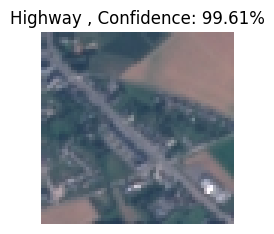

True label: AnnualCrop


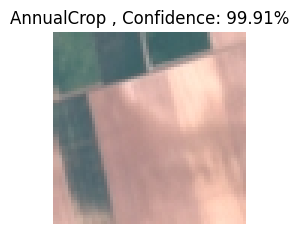

True label: SeaLake


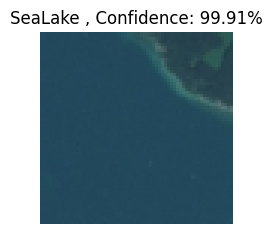

In [24]:
# Show a few random test images with the reloaded model's predictions
for _ in range(3):
    random_index = np.random.randint(0, len(test_data))
    img, label = test_data[random_index]
    print(f'True label: {class_names[label]}')
    predictOne(saved_model, img, class_names)

## Acknowledgements

The dataset used in this project is **EuroSAT**, derived from Sentinel-2 imagery published by the European Space Agency and accessed through [Kaggle](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset). The original benchmark was introduced by Helber et al. (2019).

The code approaches follows the course materials by **Rifath Mahmud**, Assistant Professor, Faculty, Dept of Computer Science, AIUB,  available at [github.com/Rifath-Mahmud/CVPR](https://github.com/Rifath-Mahmud/CVPR). 

AI assistance was used for brainstorming the dataset choice and model design, for formatting the documentation, and for debugging code errors. All code was run, verified and interpreted by the author. 